# 1. Setup

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image, ImageOps
from transformers import AutoModelForImageClassification
import colorsys
import matplotlib.pyplot as plt

DATA_ROOT = "/Users/Jakub/Desktop/School/VISAI/hagrid-sample-30k-384p/hagrid_30k"
METADATA_CSV = "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/base results and setup/test_set_merged.csv"
MODEL_PATH = "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/model"
CLASSES = ["call", "dislike", "fist", "four", "like"]
BATCH_SIZE = 32

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def find_path(img_id, label):
    pattern = os.path.join(DATA_ROOT, f"train_val_{label}", f"{img_id}.*")
    matches = glob.glob(pattern)
    return matches[0] if matches else None

meta = pd.read_csv(METADATA_CSV)
meta["path"] = meta.apply(lambda r: find_path(r["id"], r["true_label"]), axis=1)
meta = meta.dropna(subset=["path"]).reset_index(drop=True)

# 2. Classify dominant background color

In [2]:
COLOR_BINS = [
    ("red", 0, 15), ("orange", 15, 45), ("yellow", 45, 65), ("green", 65, 170),
    ("cyan", 170, 200), ("blue", 200, 255), ("purple", 255, 290), ("pink", 290, 345), ("red", 345, 360),
]

def hue_to_name(h_deg):
    for name, lo, hi in COLOR_BINS:
        if lo <= h_deg < hi:
            return name
    return "red"

def dominant_background_color(path, border_frac=0.1):
    img = np.array(Image.open(path).convert("RGB")) / 255.0
    h, w, _ = img.shape
    border_px = np.concatenate([
        img[:int(h * border_frac), :, :].reshape(-1, 3),
        img[int(h * (1 - border_frac)):, :, :].reshape(-1, 3),
    ])

    hsv = np.array([colorsys.rgb_to_hsv(*px) for px in border_px])
    sat = hsv[:, 1]
    val = hsv[:, 2]

    colorful = sat > 0.15
    if colorful.sum() < len(hsv) * 0.1:
        return "white" if val.mean() > 0.6 else ("black" if val.mean() < 0.3 else "gray")

    mean_hue_deg = (hsv[colorful, 0].mean() * 360)
    return hue_to_name(mean_hue_deg)

meta["bg_color"] = meta["path"].apply(dominant_background_color)
print(meta["bg_color"].value_counts())
meta.to_csv("test_set_with_bg_color.csv", index=False)

bg_color
green     406
orange    227
yellow    149
blue       81
cyan       77
white      22
gray       17
purple     12
pink        7
red         2
Name: count, dtype: int64


# 3. Accuracy and confidence by background color

          accuracy    n
bg_color               
green     0.886700  406
orange    0.845815  227
yellow    0.872483  149
blue      0.876543   81
cyan      0.870130   77
white     0.863636   22
gray      0.941176   17
purple    0.583333   12
pink      1.000000    7
red       1.000000    2


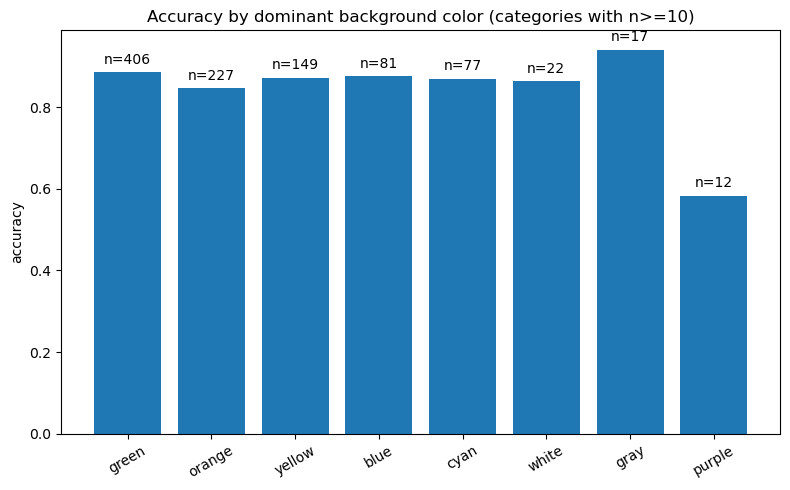

In [3]:
summary = meta.groupby("bg_color").agg(accuracy=("correct", "mean"), n=("correct", "size")).sort_values("n", ascending=False)
print(summary)

summary = summary[summary["n"] >= 10]
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(summary.index, summary["accuracy"])
for i, (acc, n) in enumerate(zip(summary["accuracy"], summary["n"])):
    ax.text(i, acc + 0.02, f"n={n}", ha="center")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy by dominant background color (categories with n>=10)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 4. Predicted class distribution by background color

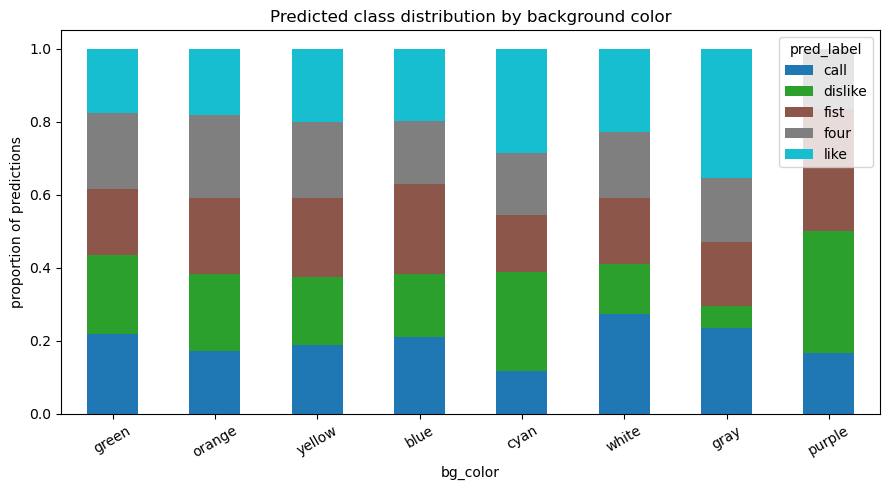

In [4]:
ct = pd.crosstab(meta["bg_color"], meta["pred_label"], normalize="index")[CLASSES]
ct = ct.loc[summary.index]

ax = ct.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab10")
ax.set_ylabel("proportion of predictions")
ax.set_title("Predicted class distribution by background color")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 5. New transform: color inversion

In [5]:
to_tensor_normalize = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def invert_colors(img):
    return ImageOps.invert(img)

def preprocess_image(path, transform_fn):
    img = Image.open(path).convert("RGB")
    img = transform_fn(img)
    return to_tensor_normalize(img)

model = AutoModelForImageClassification.from_pretrained(MODEL_PATH).to(device)
model.eval()

def run_inference(df, transform_fn):
    all_probs = []
    paths = df["path"].tolist()
    for i in range(0, len(paths), BATCH_SIZE):
        batch_paths = paths[i:i + BATCH_SIZE]
        pixel_values = torch.stack([preprocess_image(p, transform_fn) for p in batch_paths]).to(device)
        with torch.no_grad():
            logits = model(pixel_values=pixel_values).logits
            probs = F.softmax(logits, dim=1).cpu().numpy()
        all_probs.append(probs)
    all_probs = np.concatenate(all_probs, axis=0)

    result = df[["id", "true_label", "leading_hand", "leading_conf", "age", "race", "gender", "bg_color"]].copy()
    for i, cls in enumerate(CLASSES):
        result[f"prob_{cls}"] = all_probs[:, i]
    result["pred_label"] = [CLASSES[i] for i in all_probs.argmax(axis=1)]
    result["confidence"] = all_probs.max(axis=1)
    result["correct"] = result["pred_label"] == result["true_label"]
    return result

inverted_results = run_inference(meta, invert_colors)
inverted_results.to_csv("test_results_color_inverted.csv", index=False)
print("inverted accuracy:", inverted_results["correct"].mean())

inverted accuracy: 0.774


# 6. Compare original vs inverted accuracy, overall and by background color

original accuracy: 0.871
inverted accuracy: 0.774


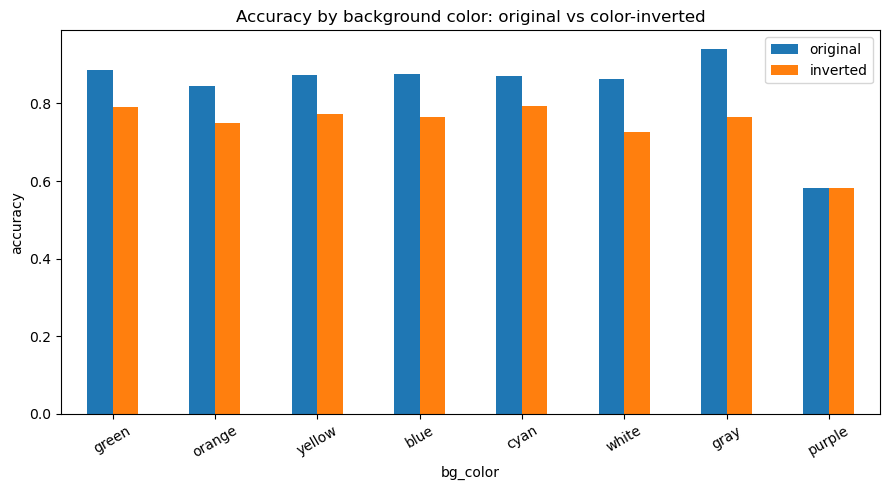

In [6]:
print("original accuracy:", meta['correct'].mean())
print("inverted accuracy:", inverted_results['correct'].mean())

comp = pd.DataFrame({
    "original": meta.groupby("bg_color")["correct"].mean(),
    "inverted": inverted_results.groupby("bg_color")["correct"].mean(),
}).loc[summary.index]

ax = comp.plot(kind="bar", figsize=(9, 5))
ax.set_ylabel("accuracy")
ax.set_title("Accuracy by background color: original vs color-inverted")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

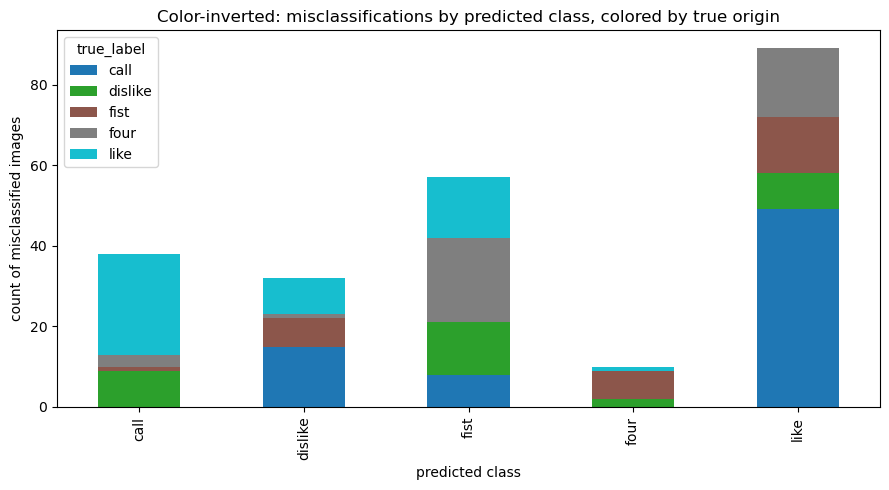

In [10]:
import matplotlib.pyplot as plt
import pandas as pd


invert_data = "/Users/Jakub/Downloads/test_results_color_inverted.csv"
d = pd.read_csv(invert_data)
CLASSES = ["call", "dislike", "fist", "four", "like"]

cm = pd.crosstab(d["true_label"], d["pred_label"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
errors_only = cm.copy()
for c in CLASSES:
    errors_only.loc[c, c] = 0  # zero out the diagonal, keep only misclassifications

ax = errors_only.T.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab10")
ax.set_xlabel("predicted class")
ax.set_ylabel("count of misclassified images")
ax.set_title("Color-inverted: misclassifications by predicted class, colored by true origin")
plt.tight_layout()
plt.show()